# STEP 3 - Data Quality

**Goal:** investigate every oddity noticed in Steps 1 and 2 and decide, with evidence, what to do with each:
**drop, fix, flag (keep but mark), or keep.**

**Why before EDA and modelling:** correlations, averages and models are all distorted by impossible or duplicated rows. We must know what is broken first.

**Rule of this step:** *investigate before acting.* A weird value is not automatically an error (a free stay can have adr = 0).
We ask: is it an error, a rare-but-real case, or an outlier, and what does it do to the thing we predict?

**Libraries:** pandas, numpy, matplotlib (charts saved as SVG only).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)

DATA = Path('..') / '..' / 'data' / 'hotel_bookings.csv'
FIG = Path('figures')          # SVG only
FIG.mkdir(exist_ok=True)

df = pd.read_csv(DATA)
ORIG = list(df.columns)        # the 32 original columns
LEAK = ['reservation_status', 'reservation_status_date', 'assigned_room_type', 'required_car_parking_spaces']  # Step 2

# helper columns (derived, not in the file)
df['total_guests'] = df['adults'] + df['children'].fillna(0) + df['babies']
df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']

def summ(mask, label):
    sub = df[mask]
    return pd.Series({'rows': len(sub), 'pct_of_data': round(len(sub) / len(df) * 100, 2),
                      'cancel_rate': round(sub['is_canceled'].mean(), 4) if len(sub) else np.nan,
                      'mean_adr': round(sub['adr'].mean(), 2) if len(sub) else np.nan}, name=label)

print(df.shape, '| overall cancel rate', round(df['is_canceled'].mean(), 4))

(119390, 34) | overall cancel rate 0.3704


## Part A - Duplicate rows

A **duplicate** is a row identical to an earlier row in all 32 columns. Two reasons to care:
1. Duplicates give some bookings extra weight in training.
2. **Leakage across the split:** if one copy lands in the training set and another in the test set, the model is tested on a row it has already seen, so the test score is inflated.

But identical rows are not always errors: two people can genuinely book the same thing (e.g. a group booking several identical rooms). So we check the evidence.

In [2]:
n_dup = df[ORIG].duplicated().sum()
print(f'Rows that are a 2nd+ copy of an earlier row: {n_dup:,} ({n_dup / len(df):.2%})')

dup_any = df[ORIG].duplicated(keep=False)
print(f'Rows belonging to any duplicate group (all copies): {dup_any.sum():,}')
print('cancel rate - rows in duplicate groups:', round(df.loc[dup_any, 'is_canceled'].mean(), 4),
      '| unique rows:', round(df.loc[~dup_any, 'is_canceled'].mean(), 4))

sizes = df[dup_any].groupby(ORIG, dropna=False).size()
print('\nnumber of distinct duplicate groups:', len(sizes))
print('copies per group (value counts of group size):')
print(sizes.value_counts().sort_index().head(8).to_string())

print('\nshare of rows in a duplicate group, by market_segment:')
print(df.assign(dup=dup_any).groupby('market_segment')['dup'].mean().round(3).sort_values(ascending=False).to_string())

Rows that are a 2nd+ copy of an earlier row: 31,994 (26.80%)
Rows belonging to any duplicate group (all copies): 40,165
cancel rate - rows in duplicate groups: 0.5839 | unique rows: 0.2622



number of distinct duplicate groups: 8171
copies per group (value counts of group size):
2    5034
3     969
4     497
5     275
6     171
7     115
8     103
9      93

share of rows in a duplicate group, by market_segment:
market_segment
Groups           0.844
Offline TA/TO    0.504
Corporate        0.278
Online TA        0.146
Direct           0.111
Complementary    0.101
Aviation         0.080
Undefined        0.000


### A2. Do identical *features* ever have different outcomes?

Modelling will not use the 4 leakage columns. After removing them, bookings can look identical to the model yet have different `is_canceled`.
Such **conflicting groups** are label noise: the model cannot be right for all of them.

In [3]:
FEATS = [c for c in ORIG if c not in LEAK + ['is_canceled']]
g = df.groupby(FEATS, dropna=False)['is_canceled'].agg(size='size', n_labels='nunique')
print('groups of feature-identical bookings:', f'{len(g):,}')
print('groups with more than one booking   :', f'{(g["size"] > 1).sum():,}')
print('groups with BOTH outcomes (conflict) :', f'{(g["n_labels"] > 1).sum():,}')
print('rows inside conflicting groups       :', f'{g.loc[g["n_labels"] > 1, "size"].sum():,}')

# how many rows are exact copies once the leakage columns are ignored
n_dup_feat = df[FEATS + ['is_canceled']].duplicated().sum()
print('\n2nd+ copies when leakage columns are ignored (features + target):', f'{n_dup_feat:,}', f'({n_dup_feat / len(df):.2%})')

groups of feature-identical bookings: 85,688
groups with more than one booking   : 8,404
groups with BOTH outcomes (conflict) : 289
rows inside conflicting groups       : 2,107



2nd+ copies when leakage columns are ignored (features + target): 33,413 (27.99%)


## Part B - Zero-guest bookings

`total_guests = adults + children + babies`. A booking with zero guests cannot be a real stay by a person. We check how many exist and what they look like.

In [4]:
zg = df['total_guests'] == 0
print(summ(zg, 'zero guests').to_string())
print('\nzero-adult rows (any children/babies):', (df['adults'] == 0).sum(),
      '| zero-adult but children or babies present:', ((df['adults'] == 0) & (df['total_guests'] > 0)).sum())
print('\nhotel:');            print(df.loc[zg, 'hotel'].value_counts().to_string())
print('\nmarket_segment:');   print(df.loc[zg, 'market_segment'].value_counts().to_string())
print('\nreservation_status:'); print(df.loc[zg, 'reservation_status'].value_counts().to_string())
print('\nadr of zero-guest rows:'); print(df.loc[zg, 'adr'].describe().round(2).to_string())
print('\ntotal_nights of zero-guest rows:'); print(df.loc[zg, 'total_nights'].describe().round(2).to_string())

rows           180.0000
pct_of_data      0.1500
cancel_rate      0.1389
mean_adr        10.4600

zero-adult rows (any children/babies): 403 | zero-adult but children or babies present: 223

hotel:
hotel
City Hotel      167
Resort Hotel     13

market_segment:
market_segment
Online TA        69
Offline TA/TO    37
Direct           24
Groups           20
Complementary    15
Corporate        13
Aviation          2

reservation_status:
reservation_status
Check-Out    155
Canceled      24
No-Show        1

adr of zero-guest rows:
count    180.00
mean      10.46
std       31.68
min        0.00
25%        0.00
50%        0.00
75%        0.00
max      200.00

total_nights of zero-guest rows:
count    180.00
mean       4.52
std        7.89
min        0.00
25%        0.00
50%        2.00
75%        6.00
max       57.00


## Part C - Zero-night stays

`total_nights = stays_in_weekend_nights + stays_in_week_nights`. A stay of 0 nights is either a same-day use, an error, or a booking that never became a stay.

In [5]:
zn = df['total_nights'] == 0
print(summ(zn, 'zero nights').to_string())
print('\nreservation_status:'); print(df.loc[zn, 'reservation_status'].value_counts().to_string())
print('\nmarket_segment:');   print(df.loc[zn, 'market_segment'].value_counts().to_string())
print('\nhotel:');            print(df.loc[zn, 'hotel'].value_counts().to_string())
print('\nadr of zero-night rows:'); print(df.loc[zn, 'adr'].describe().round(2).to_string())
print('\noverlap: zero nights AND zero guests:', (zn & zg).sum())
print('overlap: zero nights AND adr == 0     :', (zn & (df['adr'] == 0)).sum())

rows           715.000
pct_of_data      0.600
cancel_rate      0.049
mean_adr         0.000

reservation_status:
reservation_status
Check-Out    680
Canceled      22
No-Show       13

market_segment:
market_segment
Online TA        312
Offline TA/TO    149
Direct           136
Corporate         53
Groups            36
Complementary     23
Aviation           6

hotel:
hotel
Resort Hotel    384
City Hotel      331

adr of zero-night rows:
count    715.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0

overlap: zero nights AND zero guests: 70
overlap: zero nights AND adr == 0     : 715


## Part D - adr problems (negative, zero, extreme)

`adr` = average daily rate (price per night). It is the regression target and also a possible feature, so bad values matter twice.

In [6]:
neg = df['adr'] < 0
print('negative adr rows:', neg.sum())
print(df.loc[neg, ['hotel', 'arrival_date_year', 'arrival_date_month', 'market_segment', 'reserved_room_type', 'total_nights', 'adr', 'reservation_status']].T.to_string())

negative adr rows: 1
                           14969
hotel               Resort Hotel
arrival_date_year           2017
arrival_date_month         March
market_segment            Groups
reserved_room_type             A
total_nights                  10
adr                        -6.38
reservation_status     Check-Out


In [7]:
zero = df['adr'] == 0
print(summ(zero, 'adr == 0').to_string())
print('\nreservation_status of adr == 0 rows:'); print(df.loc[zero, 'reservation_status'].value_counts().to_string())
print('\nmarket_segment of adr == 0 rows (count) and share of each segment that has adr == 0:')
t = pd.DataFrame({'adr0_rows': df.loc[zero, 'market_segment'].value_counts(),
                  'segment_rows': df['market_segment'].value_counts()}).fillna(0).astype(int)
t['share_adr0_in_segment'] = (t['adr0_rows'] / t['segment_rows']).round(3)
print(t.sort_values('adr0_rows', ascending=False).to_string())
print('\nadr == 0 and total_nights == 0:', (zero & zn).sum(), '| adr == 0 and total_nights > 0:', (zero & ~zn).sum())

rows           1959.0000
pct_of_data       1.6400
cancel_rate       0.1087
mean_adr          0.0000

reservation_status of adr == 0 rows:
reservation_status
Check-Out    1746
Canceled      187
No-Show        26

market_segment of adr == 0 rows (count) and share of each segment that has adr == 0:
                adr0_rows  segment_rows  share_adr0_in_segment
market_segment                                                
Complementary         680           743                  0.915
Online TA             367         56477                  0.006
Offline TA/TO         332         24219                  0.014
Groups                252         19811                  0.013
Direct                240         12606                  0.019
Corporate              82          5295                  0.015
Aviation                6           237                  0.025
Undefined               0             2                  0.000

adr == 0 and total_nights == 0: 715 | adr == 0 and total_nights > 0: 124

In [8]:
print('adr quantiles:'); print(df['adr'].quantile([0.5, 0.9, 0.99, 0.999, 0.9999, 1.0]).round(2).to_string())
print('\ntop 6 adr rows:')
print(df.nlargest(6, 'adr')[['hotel', 'arrival_date_year', 'arrival_date_month', 'market_segment', 'reserved_room_type',
                             'adults', 'total_nights', 'adr', 'is_canceled']].to_string())
print('\nadr by hotel (median, 99th percentile, max):')
print(df.groupby('hotel')['adr'].agg(median='median', p99=lambda s: s.quantile(0.99), max='max').round(2).to_string())
print('\nrows with adr > 300:', (df['adr'] > 300).sum(), '| adr > 500:', (df['adr'] > 500).sum(), '| adr > 1000:', (df['adr'] > 1000).sum())

adr quantiles:
0.5000      94.58
0.9000     164.00
0.9900     252.00
0.9990     326.20
0.9999     388.00
1.0000    5400.00

top 6 adr rows:
               hotel  arrival_date_year arrival_date_month market_segment reserved_room_type  adults  total_nights     adr  is_canceled
48515     City Hotel               2016              March  Offline TA/TO                  A       2             1  5400.0            1
111403    City Hotel               2017                May  Offline TA/TO                  A       1             1   510.0            0
15083   Resort Hotel               2015               July      Corporate                  A       2             1   508.0            0
103912    City Hotel               2016           December         Direct                  E       2             2   451.5            0
13142   Resort Hotel               2017             August      Online TA                  A       2            14   450.0            1
13391   Resort Hotel               2017     

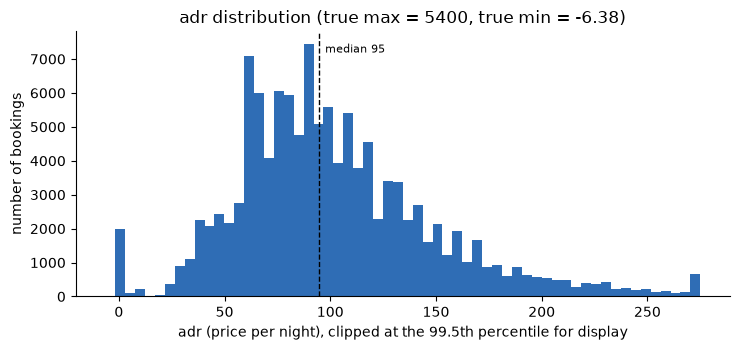

In [9]:
x = df['adr'].clip(upper=df['adr'].quantile(0.995))   # clip only for display so the extreme row does not squash the chart
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.hist(x, bins=60, color='#2F6DB5')
ax.axvline(df['adr'].median(), color='black', linestyle='--', linewidth=1)
ax.text(df['adr'].median() + 3, ax.get_ylim()[1] * 0.92, f'median {df["adr"].median():.0f}', fontsize=8)
ax.set_xlabel('adr (price per night), clipped at the 99.5th percentile for display')
ax.set_ylabel('number of bookings')
ax.set_title(f'adr distribution (true max = {df["adr"].max():.0f}, true min = {df["adr"].min():.2f})')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(FIG / 'step3_adr_distribution.svg')
plt.show()

## Part E - Other extreme values

For each numeric column we look at the median, the 99th percentile, the 99.9th percentile and the maximum.
If the maximum is far above the 99.9th percentile, a handful of rows are extreme. Then we count rows above sensible thresholds.

In [10]:
cols = ['lead_time', 'adults', 'children', 'babies', 'total_nights', 'days_in_waiting_list',
        'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes']
q = df[cols].quantile([0.5, 0.99, 0.999, 1.0]).T
q.columns = ['median', 'p99', 'p99.9', 'max']
print(q.round(2).to_string())

print('\nrows above sensible thresholds:')
thr = {'adults >= 5': df['adults'] >= 5, 'children >= 4': df['children'] >= 4, 'babies >= 3': df['babies'] >= 3,
       'total_nights >= 15': df['total_nights'] >= 15, 'lead_time >= 500': df['lead_time'] >= 500,
       'days_in_waiting_list >= 200': df['days_in_waiting_list'] >= 200}
print(pd.DataFrame([summ(m, k) for k, m in thr.items()]).to_string())

                                median    p99   p99.9    max
lead_time                         69.0  444.0  605.00  737.0
adults                             2.0    3.0    3.00   55.0
children                           0.0    2.0    2.00   10.0
babies                             0.0    0.0    1.00   10.0
total_nights                       3.0   14.0   25.00   69.0
days_in_waiting_list               0.0   75.0  231.33  391.0
previous_cancellations             0.0    1.0   14.00   26.0
previous_bookings_not_canceled     0.0    3.0   22.00   72.0
booking_changes                    0.0    3.0    6.00   21.0

rows above sensible thresholds:
                              rows  pct_of_data  cancel_rate  mean_adr
adults >= 5                   16.0         0.01       1.0000      0.00
children >= 4                  1.0         0.00       1.0000    133.16
babies >= 3                    2.0         0.00       0.0000     89.72
total_nights >= 15           439.0         0.37       0.5535     78.31
le

## Part F - Looking at the actual rows behind the findings

Numbers can mislead; real rows show what is going on. First: the largest duplicate groups. If they look like one organisation booking many identical rooms,
the duplicates are real bookings, not copy errors.

In [11]:
top = sizes.sort_values(ascending=False).head(6)
tf = top.index.to_frame(index=False)
tf['copies'] = top.values
tf['total_nights'] = tf['stays_in_weekend_nights'] + tf['stays_in_week_nights']
print(tf[['copies', 'hotel', 'market_segment', 'lead_time', 'arrival_date_year', 'arrival_date_month',
          'arrival_date_day_of_month', 'adults', 'total_nights', 'adr', 'is_canceled']].to_string(index=False))

 copies      hotel market_segment  lead_time  arrival_date_year arrival_date_month  arrival_date_day_of_month  adults  total_nights   adr  is_canceled
    180 City Hotel         Groups        277               2016           November                          7       2             3 100.0            1
    150 City Hotel         Groups         68               2016           February                         17       2             2  75.0            1
    109 City Hotel  Offline TA/TO        188               2016               June                         15       1             2 130.0            1
    101 City Hotel         Groups        158               2016                May                         24       1             2 130.0            1
    100 City Hotel  Offline TA/TO         34               2015           December                          8       1             2  90.0            1
     99 City Hotel         Groups        156               2017              April            

Second: the rows with implausible guest counts (5+ adults, 4+ children, 3+ babies).

In [12]:
big_adults = df['adults'] >= 5
odd_kids = (df['children'] >= 4) | (df['babies'] >= 3)
print(df.loc[big_adults | odd_kids, ['hotel', 'market_segment', 'adults', 'children', 'babies', 'total_nights', 'adr',
                                     'is_canceled', 'reservation_status']].sort_values('adults', ascending=False).to_string())

              hotel market_segment  adults  children  babies  total_nights     adr  is_canceled reservation_status
2173   Resort Hotel         Direct      55       0.0       0             2    0.00            1           Canceled
1643   Resort Hotel         Direct      50       0.0       0             3    0.00            1           Canceled
1539   Resort Hotel         Direct      40       0.0       0             3    0.00            1           Canceled
1962   Resort Hotel         Direct      27       0.0       0             4    0.00            1           Canceled
1917   Resort Hotel         Direct      27       0.0       0             4    0.00            1           Canceled
1884   Resort Hotel  Offline TA/TO      26       0.0       0             7    0.00            1           Canceled
1587   Resort Hotel  Offline TA/TO      26       0.0       0             7    0.00            1           Canceled
2003   Resort Hotel  Offline TA/TO      26       0.0       0             7    0.

## Part G - Decisions and the cleaned dataset (v1)

**Row-removal rules** (only for rows that are impossible or meaningless, defined by the *values*, never by whether the booking was cancelled):

| Rule | Why |
|---|---|
| zero guests | a booking with nobody in it is not a real stay |
| zero nights | not an overnight stay; all have adr = 0, consistent with price = revenue / nights being undefined for 0 nights |
| negative adr | a price cannot be negative |
| adr = 5400 | ten times the next highest value: almost certainly an entry error |
| 5+ adults | all have adr = 0 and are all cancelled: placeholder-like records |
| 4+ children or 3+ babies | implausible counts |

Everything else stays. Statistical fixes (filling missing values, encoding, scaling) are NOT done here - they are done in Step 6 **after** the train/test split so the test set never influences them.

In [13]:
zero_adr_pos_nights = (df['adr'] == 0) & (df['total_nights'] > 0)
rules = {
    'zero guests (adults+children+babies = 0)': df['total_guests'] == 0,
    'zero nights (weekend+week nights = 0)': df['total_nights'] == 0,
    'negative adr': df['adr'] < 0,
    'adr > 1000 (the 5400 row)': df['adr'] > 1000,
    'adults >= 5': big_adults,
    'children >= 4 or babies >= 3': odd_kids,
}
seen = pd.Series(False, index=df.index)
log_rows = []
for name, m in rules.items():
    new_rows = m & ~seen
    log_rows.append({'rule': name, 'rows_flagged': int(m.sum()), 'additional_unique_rows_removed': int(new_rows.sum())})
    seen |= m
removal_log = pd.DataFrame(log_rows)
drop_mask = seen
print(removal_log.to_string(index=False))
print(f'\nTotal rows removed: {drop_mask.sum():,} of {len(df):,} ({drop_mask.mean():.2%})')
print('cancel rate - removed rows:', round(df.loc[drop_mask, 'is_canceled'].mean(), 4),
      '| kept rows:', round(df.loc[~drop_mask, 'is_canceled'].mean(), 4))

clean = df.loc[~drop_mask, ORIG]
out_csv = DATA.parent / 'hotel_bookings_clean_v1.csv'
clean.to_csv(out_csv, index=False)
removal_log.to_csv('STEP_3_row_removal_log.csv', index=False)
print(f'\nclean_v1 saved: {len(clean):,} rows x {clean.shape[1]} columns -> {out_csv.name}')
print('cancel rate after cleaning:', round(clean['is_canceled'].mean(), 4))
print('regression rows (adr > 0):', f'{(clean["adr"] > 0).sum():,}', '| adr == 0 rows kept for classification only:', f'{(clean["adr"] == 0).sum():,}')

# sanity checks: none of the removed patterns remain
c_guests = clean['adults'] + clean['children'].fillna(0) + clean['babies']
c_nights = clean['stays_in_weekend_nights'] + clean['stays_in_week_nights']
assert (c_guests > 0).all() and (c_nights > 0).all() and (clean['adr'] >= 0).all() and (clean['adr'] <= 1000).all()
print('sanity checks passed')

                                    rule  rows_flagged  additional_unique_rows_removed
zero guests (adults+children+babies = 0)           180                             180
   zero nights (weekend+week nights = 0)           715                             645
                            negative adr             1                               1
               adr > 1000 (the 5400 row)             1                               1
                             adults >= 5            16                              16
            children >= 4 or babies >= 3             3                               3

Total rows removed: 846 of 119,390 (0.71%)
cancel rate - removed rows: 0.078 | kept rows: 0.3725



clean_v1 saved: 118,544 rows x 32 columns -> hotel_bookings_clean_v1.csv
cancel rate after cleaning: 0.3725
regression rows (adr > 0): 117,395 | adr == 0 rows kept for classification only: 1,149
sanity checks passed


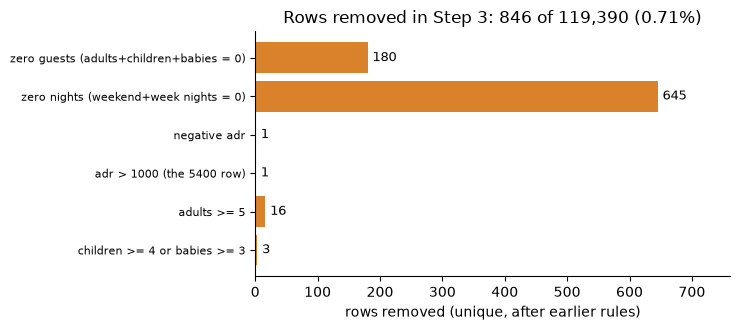

In [14]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
lab = removal_log['rule']
vals = removal_log['additional_unique_rows_removed']
y = np.arange(len(lab))[::-1]
ax.barh(y, vals, color='#D9822B')
ax.set_yticks(y)
ax.set_yticklabels(lab, fontsize=8)
for yi, v in zip(y, vals):
    ax.text(v + 8, yi, f'{v:,}', va='center', fontsize=9)
ax.set_xlim(0, vals.max() * 1.18)
ax.set_xlabel('rows removed (unique, after earlier rules)')
ax.set_title(f'Rows removed in Step 3: {drop_mask.sum():,} of {len(df):,} ({drop_mask.mean():.2%})')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(FIG / 'step3_rows_removed_per_rule.svg')
plt.show()

## Part H - The full decision table

Every issue found in Step 3, with the decision and the reason. "Applied in" says where the action actually happens.

In [15]:
n_dup_rows = int(df[ORIG].duplicated().sum())
decisions = pd.DataFrame([
    ('Full-row duplicates (2nd+ copies)', n_dup_rows, 'KEEP all rows',
     'Concentrated in Groups (84% of rows) and Offline TA/TO (50%): looks like real batch bookings. Dropping would remove real behaviour. Risk: copies in both train and test inflate the score.',
     'Step 6: group-aware split (identical-feature bookings stay on one side); sensitivity test with duplicates dropped'),
    ('Feature-identical bookings with different outcomes', int(g.loc[g['n_labels'] > 1, 'size'].sum()), 'KEEP',
     'About 1.8% of rows: irreducible label noise that limits the best possible score.', 'Step 8: remember when judging model scores'),
    ('Zero guests', int(rules['zero guests (adults+children+babies = 0)'].sum()), 'DROP', 'Not a real stay.', 'Step 3 (clean_v1)'),
    ('Zero nights', int(rules['zero nights (weekend+week nights = 0)'].sum()), 'DROP', 'Not an overnight stay; adr = 0 for all (price undefined).', 'Step 3 (clean_v1)'),
    ('Negative adr', int(rules['negative adr'].sum()), 'DROP', 'Price cannot be negative.', 'Step 3 (clean_v1)'),
    ('adr = 5400', int(rules['adr > 1000 (the 5400 row)'].sum()), 'DROP', 'Ten times the next highest value.', 'Step 3 (clean_v1)'),
    ('5+ adults', int(big_adults.sum()), 'DROP', 'All adr = 0 and all cancelled: placeholder-like.', 'Step 3 (clean_v1)'),
    ('4+ children or 3+ babies', int(odd_kids.sum()), 'DROP', 'Implausible counts.', 'Step 3 (clean_v1)'),
    ('adr = 0 with nights > 0', int(zero_adr_pos_nights.sum()), 'KEEP for classification, EXCLUDE from regression',
     'Complementary segment: 91.5% of its rows have adr 0 (free stays by design). Others unexplained. A free stay is a real booking but not a price.', 'Step 6: regression uses adr > 0 only'),
    ('adults = 0 but children/babies present', int(((df['adults'] == 0) & (df['total_guests'] > 0)).sum()), 'KEEP',
     '0.19% of rows; low impact. Revisit if errors concentrate here.', '-'),
    ('adr > 300 (but not the 5400 row)', int(((df['adr'] > 300) & (df['adr'] < 1000)).sum()), 'KEEP',
     'Plausible peak or suite prices (99th percentile is about 250-280).', 'Step 8: RMSE is sensitive to these; consider log(adr)'),
    ('lead_time >= 500', int(thr['lead_time >= 500'].sum()), 'KEEP', 'Real, and a strong signal (85.7% cancel).', 'Step 6: maybe log or cap for linear models'),
    ('total_nights >= 15', int(thr['total_nights >= 15'].sum()), 'KEEP', 'Long stays are plausible.', '-'),
    ('days_in_waiting_list >= 200', int(thr['days_in_waiting_list >= 200'].sum()), 'KEEP', 'Plausible; the column is excluded from the main model anyway (Step 2).', '-'),
    ('Missing: company (94.31%)', int(df['company'].isna().sum()), 'PLAN: has_company flag', 'IDs; almost empty.', 'Step 6'),
    ('Missing: agent (13.69%)', int(df['agent'].isna().sum()), 'PLAN: category "no agent"', 'IDs; missing probably means no agent.', 'Step 6'),
    ('Missing: country (0.41%)', int(df['country'].isna().sum()), 'PLAN: category "Unknown"', 'Small gap.', 'Step 6'),
    ('Missing: children (4 rows)', int(df['children'].isna().sum()), 'PLAN: fill with 0', 'Median is 0; only 4 rows.', 'Step 6 (fit on training data only)'),
    ('Undefined: meal', int((df['meal'] == 'Undefined').sum()), 'PLAN: merge with SC', 'Documentation says both mean no meal package.', 'Step 6'),
    ('Undefined: market_segment, distribution_channel', int((df['market_segment'] == 'Undefined').sum() + (df['distribution_channel'] == 'Undefined').sum()),
     'PLAN: keep as its own category', 'Only a handful of rows.', 'Step 6'),
], columns=['issue', 'rows', 'decision', 'reason', 'applied_in'])
decisions.to_csv('STEP_3_quality_decisions.csv', index=False)
decisions[['issue', 'rows', 'decision']]

,issue,rows,decision
0,Full-row duplicates (2nd+ copies),31994,KEEP all rows
1,Feature-identical bookings with different outc...,2107,KEEP
2,Zero guests,180,DROP
3,Zero nights,715,DROP
4,Negative adr,1,DROP
5,adr = 5400,1,DROP
6,5+ adults,16,DROP
7,4+ children or 3+ babies,3,DROP
8,adr = 0 with nights > 0,1244,"KEEP for classification, EXCLUDE from regression"
9,adults = 0 but children/babies present,223,KEEP


## Summary of Step 3

- Rows removed (impossible or meaningless): see the removal log above. Result: `data/hotel_bookings_clean_v1.csv`.
- Duplicates are **kept** (they look like real group bookings) but need a group-aware train/test split in Step 6.
- adr = 0 rows are kept for classification but excluded from the regression task.
- Missing-value and Undefined handling is planned for Step 6 (after the split, to avoid leakage).